# Credit Card fraud detection 


### Importing the dependies 

In [2]:
import numpy as np  #used for working with arrays
import pandas as pd  #used for working with dataset
import seaborn as sns 
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split  #allows us to split data into training data and testing data
from sklearn.linear_model import LogisticRegression  #logistic regression model
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score #help us to check the performance of the model
from sklearn.tree import DecisionTreeClassifier #Decision Tree
from sklearn.ensemble import RandomForestClassifier #Random Forest


In [3]:
#loading the dataset to a pandas dataframe

creditCard_data = pd.read_csv("creditcard.csv")


In [4]:
# First five rows of dataset

creditCard_data.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [5]:
# Last five rows of dataset

creditCard_data.tail()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,...,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0


In [6]:
# dataset information

creditCard_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [7]:
#check the number of missing values in each column

creditCard_data.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [8]:
# distribution of legit transaction & fraudulent transaction 

distri = pd.DataFrame({
    'Legit Transactions :' : [creditCard_data['Class'].value_counts().get(0)],
    'Fraud Transactions :' : [creditCard_data['Class'].value_counts().get(1)]
}).transpose()
 
distri.columns = ['Transactions']

distri

,Transactions
Legit Transactions :,284315
Fraud Transactions :,492


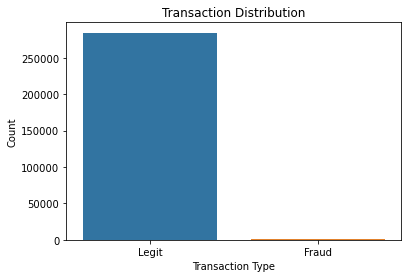

In [9]:
# Displaying the bar chart of the data

creditCard_data['Class Label'] = creditCard_data['Class'].map({0: 'Legit', 1: 'Fraud'})

# Plot the countplot
sns.countplot(x='Class Label', data=creditCard_data)
plt.title('Transaction Distribution')
plt.xlabel('Transaction Type')
plt.ylabel('Count')
plt.show()

### This dataset is highly Imbalanced

In [10]:
#separating the data for analysis

legit = creditCard_data[creditCard_data.Class == 0]
fraud = creditCard_data[creditCard_data.Class == 1]

In [11]:
print(legit.shape)
print(fraud.shape)

(284315, 32)
(492, 32)


In [12]:
# statistical measures of the data

legit.Amount.describe()

count    284315.000000
mean         88.291022
std         250.105092
min           0.000000
25%           5.650000
50%          22.000000
75%          77.050000
max       25691.160000
Name: Amount, dtype: float64

In [13]:
fraud.Amount.describe()

count     492.000000
mean      122.211321
std       256.683288
min         0.000000
25%         1.000000
50%         9.250000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64

#### We calculate the mean value of both the fraud and legit transaction , 
#### so that our model is able to recognize between fraudelent and legit transactions 

In [14]:
# compare the value for both the transcations

creditCard_data.groupby('Class Label').mean()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
Class Label,,,,,,,,,,,,,,,,,,,,,
Fraud,80746.806911,-4.771948,3.623778,-7.033281,4.542029,-3.151225,-1.397737,-5.568731,0.570636,-2.581123,...,0.713588,0.014049,-0.040308,-0.105130,0.041449,0.051648,0.170575,0.075667,122.211321,1.0
Legit,94838.202258,0.008258,-0.006271,0.012171,-0.007860,0.005453,0.002419,0.009637,-0.000987,0.004467,...,-0.001235,-0.000024,0.000070,0.000182,-0.000072,-0.000089,-0.000295,-0.000131,88.291022,0.0


## Under-sampling 
### Build a sample dataset containing similar distribution of normal transactions and fraudulent transactions
### Number of Fradulent transactions-> 492

In [15]:
legit_sample = legit.sample(n=492)
# we create a sample of legit dataframe of random 492 values 

### Concatenating two dataframes 

In [16]:
new_dataset = pd.concat([legit_sample, fraud], axis = 0)
new_dataset.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Class,Class Label
147561,88686.0,-2.235620,1.969541,-0.236131,-0.710860,0.950030,-0.726242,1.123119,-0.441021,0.567697,...,0.481693,-0.483020,-0.786400,1.184045,0.092556,-0.507751,0.227385,6.30,0,Legit
149638,91626.0,2.264174,-0.676247,-2.567089,-2.434082,0.567833,-0.727851,0.119097,-0.507534,0.981378,...,-0.242468,-0.050972,-0.221272,0.427990,-0.113109,-0.063926,-0.084288,30.23,0,Legit
47532,43248.0,1.236154,0.296612,0.189732,0.500236,-0.151179,-0.559666,-0.020861,-0.037502,-0.209391,...,-0.775488,0.075782,-0.036074,0.230777,0.097189,-0.027156,0.017416,1.98,0,Legit
252793,155970.0,2.067028,-0.164936,-1.122719,0.416874,-0.255738,-1.217065,0.073947,-0.240116,0.787728,...,-0.840829,0.352492,-0.068034,-0.343927,0.205191,-0.081105,-0.064132,0.99,0,Legit
22842,32458.0,1.348751,-0.773204,1.218122,-0.431681,-1.633691,-0.413911,-1.150647,0.034451,0.008753,...,0.456634,-0.014052,0.413491,0.362710,-0.196209,0.054397,0.027236,9.08,0,Legit


In [17]:
new_dataset.tail()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Class,Class Label
279863,169142.0,-1.927883,1.125653,-4.518331,1.749293,-1.566487,-2.010494,-0.882850,0.697211,-2.064945,...,-0.319189,0.639419,-0.294885,0.537503,0.788395,0.292680,0.147968,390.00,1,Fraud
280143,169347.0,1.378559,1.289381,-5.004247,1.411850,0.442581,-1.326536,-1.413170,0.248525,-1.127396,...,0.028234,-0.145640,-0.081049,0.521875,0.739467,0.389152,0.186637,0.76,1,Fraud
280149,169351.0,-0.676143,1.126366,-2.213700,0.468308,-1.120541,-0.003346,-2.234739,1.210158,-0.652250,...,0.834108,0.190944,0.032070,-0.739695,0.471111,0.385107,0.194361,77.89,1,Fraud
281144,169966.0,-3.113832,0.585864,-5.399730,1.817092,-0.840618,-2.943548,-2.208002,1.058733,-1.632333,...,-0.269209,-0.456108,-0.183659,-0.328168,0.606116,0.884876,-0.253700,245.00,1,Fraud
281674,170348.0,1.991976,0.158476,-2.583441,0.408670,1.151147,-0.096695,0.223050,-0.068384,0.577829,...,-0.295135,-0.072173,-0.450261,0.313267,-0.289617,0.002988,-0.015309,42.53,1,Fraud


In [20]:
# new_dataset distribution of legit transaction & fraudulent transaction 

distri = pd.DataFrame({
    'Legit Transactions :' : [new_dataset['Class'].value_counts().get(0)],
    'Fraud Transactions :' : [new_dataset['Class'].value_counts().get(1)]
}).transpose()

distri.columns = ['Transactions']

distri

,Transactions
Legit Transactions :,492
Fraud Transactions :,492


In [21]:
# compare the value for both the transcations

new_dataset.groupby('Class Label').mean()
#The mean values of new_dataset has not changed much from original dataset

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
Class Label,,,,,,,,,,,,,,,,,,,,,
Fraud,80746.806911,-4.771948,3.623778,-7.033281,4.542029,-3.151225,-1.397737,-5.568731,0.570636,-2.581123,...,0.713588,0.014049,-0.040308,-0.105130,0.041449,0.051648,0.170575,0.075667,122.211321,1.0
Legit,97371.843496,-0.065359,-0.113191,-0.008272,-0.040562,-0.061418,-0.027092,0.006683,0.023458,0.023384,...,0.045363,-0.004666,0.022252,-0.033793,0.005132,-0.003695,-0.016895,0.003864,107.550610,0.0


In [22]:
new_dataset = new_dataset.drop(columns=['Class Label'])


### Splitting the data into features & targets

In [23]:
X = new_dataset.drop(columns='Class', axis = 1)

Y = new_dataset['Class']

In [24]:
print(X)

            Time        V1        V2        V3        V4        V5        V6  \
147561   88686.0 -2.235620  1.969541 -0.236131 -0.710860  0.950030 -0.726242   
149638   91626.0  2.264174 -0.676247 -2.567089 -2.434082  0.567833 -0.727851   
47532    43248.0  1.236154  0.296612  0.189732  0.500236 -0.151179 -0.559666   
252793  155970.0  2.067028 -0.164936 -1.122719  0.416874 -0.255738 -1.217065   
22842    32458.0  1.348751 -0.773204  1.218122 -0.431681 -1.633691 -0.413911   
...          ...       ...       ...       ...       ...       ...       ...   
279863  169142.0 -1.927883  1.125653 -4.518331  1.749293 -1.566487 -2.010494   
280143  169347.0  1.378559  1.289381 -5.004247  1.411850  0.442581 -1.326536   
280149  169351.0 -0.676143  1.126366 -2.213700  0.468308 -1.120541 -0.003346   
281144  169966.0 -3.113832  0.585864 -5.399730  1.817092 -0.840618 -2.943548   
281674  170348.0  1.991976  0.158476 -2.583441  0.408670  1.151147 -0.096695   

              V7        V8        V9  .

In [25]:
print(Y)

147561    0
149638    0
47532     0
252793    0
22842     0
         ..
279863    1
280143    1
280149    1
281144    1
281674    1
Name: Class, Length: 984, dtype: int64


## Split the data into Training data & Test data

In [26]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, stratify= Y, random_state=2)

# here we split the data into four variables 
# X_train has the training dataset compromising of 80% of the original data
# Y_train has the corresponding label for the training data
# X_test is the test data compromising 20% of the original data
# Y_test is the corresponding label for the test data


In [27]:
print(X.shape, X_train.shape, X_test.shape)

(984, 30) (787, 30) (197, 30)


## Model Training 
### Logistic Regression 

In [28]:
lr_model = LogisticRegression()

In [29]:
# training the logistic Regression model with training data
lr_model = LogisticRegression(max_iter=500)  # Increase iterations
lr_model.fit(X_train, Y_train)


LogisticRegression(max_iter=500)

## Model Evaluation 
## Accuracy Score of Logistic Regression 

In [30]:
# accuracy on training data
X_train_predictionlr = lr_model.predict(X_train) 
# the prediction of the model is stored in this variable
training_data_accuracylr = accuracy_score(X_train_predictionlr, Y_train)
# the accuracy of the training data is compared with the original data here

print(training_data_accuracylr)

0.940279542566709


In [31]:
# accuracy on test data
X_test_predictionlr = lr_model.predict(X_test)
test_data_accuracylr = accuracy_score(X_test_predictionlr, Y_test)

print(test_data_accuracylr)

0.9441624365482234


In [32]:
lr_result = pd.DataFrame(["Linear Regression",training_data_accuracylr, test_data_accuracylr]).transpose()
lr_result.columns = ['Model','Trainig data accuracy','Test data accuracy']
lr_result

,Model,Trainig data accuracy,Test data accuracy
0,Linear Regression,0.94028,0.944162


## Decision Tree

In [34]:
dt_model = DecisionTreeClassifier()

# Apply constraints to reduce overfitting
dt_model = DecisionTreeClassifier(max_depth=5, min_samples_split=10, min_samples_leaf=5)

In [35]:
# Train the Decision Tree model
dt_model.fit(X_train, Y_train)

DecisionTreeClassifier(max_depth=5, min_samples_leaf=5, min_samples_split=10)

## Accuracy Score of Decision Tree

In [38]:
# accuracy on training data
X_train_predictiondt = dt_model.predict(X_train) 
# the prediction of the model is stored in this variable
training_data_accuracydt = accuracy_score(X_train_predictiondt, Y_train)
# the accuracy of the training data is compared with the original data here


print(training_data_accuracydt)

0.9593392630241423


In [39]:
# accuracy on test data
X_test_predictiondt = dt_model.predict(X_test)
test_data_accuracydt = accuracy_score(X_test_predictiondt, Y_test)


print(test_data_accuracydt)

0.8781725888324873


In [40]:
dt_result = pd.DataFrame(["Decision Tree",training_data_accuracydt, test_data_accuracydt]).transpose()
dt_result.columns = ['Model','Trainig data accuracy','Test data accuracy']
dt_result

,Model,Trainig data accuracy,Test data accuracy
0,Decision Tree,0.959339,0.878173


## Random Forest

In [41]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
# Apply constraints to reduce overfitting
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)


In [42]:
# Train the Random Forest model
rf_model.fit(X_train, Y_train)

RandomForestClassifier(max_depth=10, random_state=42)

## Accuracy Score of Random Forest

In [44]:
# accuracy on training data
X_train_predictionrf = rf_model.predict(X_train)
training_data_accuracyrf = accuracy_score(Y_train, X_train_predictionrf)


print(training_data_accuracyrf)

0.9911054637865311


In [45]:
# accuracy on test data
X_test_predictionrf = rf_model.predict(X_test)
test_data_accuracyrf = accuracy_score(Y_test, X_test_predictionrf)


print(test_data_accuracyrf)

0.9289340101522843


In [46]:
rf_result = pd.DataFrame(["Random Forest",training_data_accuracyrf, test_data_accuracyrf]).transpose()
rf_result.columns = ['Model','Trainig data accuracy','Test data accuracy']
rf_result

,Model,Trainig data accuracy,Test data accuracy
0,Random Forest,0.991105,0.928934


## Model Comparison

In [47]:
df_models = pd.concat([lr_result,dt_result, rf_result], axis=0)
df_models

,Model,Trainig data accuracy,Test data accuracy
0,Linear Regression,0.94028,0.944162
0,Decision Tree,0.959339,0.878173
0,Random Forest,0.991105,0.928934
